# SOM example — clustering the Hip Hop collection by era

This notebook analyses a **collection of pieces** with a **Self-Organizing Map
(SOM)** using features extracted by `comsar`'s `TimbreTrack`.

A SOM maps high-dimensional feature vectors onto a small 2-D grid of units while
preserving topology: pieces with similar timbre land close together. A SOM is a
**dimensionality reduction**, so the map must have **fewer units than there are
pieces** (otherwise it just memorises them — see section 4). We use it to ask a
musicological question: **do the three eras of US Hip Hop separate by timbre?**

**Collection.** US Hip Hop grouped into three eras (the *Jahrgang* / year
groups):

| era | tracks |
|-----|--------|
| 1985-1998 | 130 |
| 1998-2010 | 130 |
| 2010-present | 127 |

**Why analysis files, not audio.** The original `.wav` files may not be
redistributed. Instead we ship one table of the *extracted features*
(`HipHop_features.csv`), from which the whole analysis runs — no audio needed.

## 1. The feature table

`HipHop_features.csv` holds **one row per track**. `TimbreTrack` produces seven
features **per time frame**; for a collection-level SOM we need one vector per
*track*, so each feature is summarised over time by its **mean** and
**standard deviation**. That gives 14 numeric columns plus the track name and
its era.

The seven `TimbreTrack` features are `SpectralCentroid`, `SpectralSpread`,
`SpectralFlux`, `Roughness`, `Sharpness`, `SPL` and `CorrelationDimension` —
the last one is the **fractal (correlation) dimension** of the signal. So each
has a `_mean` and a `_std` column (e.g. `Sharpness_std`). Section 8 shows how
the table was built.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold

from apollon.som.som import IncrementalMap
from apollon.som.utilities import best_match

In [2]:
data = pd.read_csv("HipHop_features.csv")
print("tracks:", len(data), " columns:", data.shape[1])
print(data.groupby("era").size())
data.head(3)

tracks: 387  columns: 16
era
1985-1998       130
1998-2010       130
2010-present    127
dtype: int64


,track,era,SpectralCentroid_mean,SpectralCentroid_std,SpectralSpread_mean,SpectralSpread_std,SpectralFlux_mean,SpectralFlux_std,Roughness_mean,Roughness_std,Sharpness_mean,Sharpness_std,SPL_mean,SPL_std,CorrelationDimension_mean,CorrelationDimension_std
0,100_GETO BOYS_STILL,1985-1998,674.978743,282.483709,1875.046404,376.509441,4.205257,1.639227,9222.500310,2164.612534,0.022621,0.005812,80.919545,4.583550,4.806141,2.097549
1,101_Scarface_I Seen a Man Die,1985-1998,1123.135431,507.808796,1974.533342,429.479357,3.912754,1.884537,8020.609349,2647.774417,0.015252,0.005563,78.691604,3.519956,4.527532,2.389898
2,102_Scarface_On My Block,1985-1998,1071.471055,1080.823672,1938.846279,712.699031,6.105980,2.823881,13054.378109,4707.627954,0.031944,0.013265,80.766354,10.211391,5.828512,3.019265


## 2. Choose the feature vector (by name, variable length)

The SOM is trained on whatever columns you list in `selected_features`, so the
vector length is **variable** — add or remove feature names freely.

In [3]:
feature_names = [c for c in data.columns if c not in ("track", "era")]
feature_names

['SpectralCentroid_mean',
 'SpectralCentroid_std',
 'SpectralSpread_mean',
 'SpectralSpread_std',
 'SpectralFlux_mean',
 'SpectralFlux_std',
 'Roughness_mean',
 'Roughness_std',
 'Sharpness_mean',
 'Sharpness_std',
 'SPL_mean',
 'SPL_std',
 'CorrelationDimension_mean',
 'CorrelationDimension_std']

### Default selection

The default below is the combination that **separates the eras best on the map**.
It was found by forward selection, scoring each candidate set by a *cross-
validated* SOM era accuracy (section 6) at the reduced map size of section 4 —
i.e. how well the map predicts a held-out track's era, with **no** overfitting
credit:

| feature set | CV era accuracy (chance = 0.33) |
|---|---|
| all 14 features | 0.53 |
| 7 means only | 0.39 |
| 7 stds only | 0.49 |
| **default (below)** | **0.59** |

Using *all* features is worse than this focused set — extra features add noise.
To try your own, edit the list, e.g. `selected_features = ["SpectralFlux_std",
"SPL_mean"]`; section 6 rescores it.

In [4]:
# Default: the combination that clusters the eras best (see table above).
selected_features = [
    "Sharpness_std",
    "Roughness_mean",
    "SpectralSpread_mean",
    "SpectralFlux_std",
    "Sharpness_mean",
]
print(f"{len(selected_features)} features selected:")
for f in selected_features:
    print("  ", f)

5 features selected:
   Sharpness_std
   Roughness_mean
   SpectralSpread_mean
   SpectralFlux_std
   Sharpness_mean


## 3. Standardize

The features live on very different scales (SPL ~80, Sharpness ~0.02). A SOM
uses Euclidean distance, so without scaling the large-valued features would
dominate. We convert every selected feature to a **z-score** (mean 0, std 1).

In [5]:
X = StandardScaler().fit_transform(data[selected_features].to_numpy())
era = data["era"].to_numpy()
X.shape

(387, 5)

## 4. Map size — a SOM must *reduce*

A SOM only reveals structure if it has **fewer units than training vectors**;
otherwise every piece gets its own unit and the map just memorises the data
(overfitting). A common rule of thumb is about `5 * sqrt(N)` units, i.e. a side
of roughly `sqrt(5 * sqrt(N))`.

For N = 387 tracks that is ~98 units → a **10x10** grid (≈ 4x fewer units than
tracks). Cross-validation confirms that bigger maps are *worse*: at 20x20 (400
units > 387) the held-out era accuracy drops to ~0.45, while 10x10 reaches
~0.53. Feel free to try `grid = 5` (a stronger reduction) or larger.

In [6]:
grid = int(round(np.sqrt(5 * np.sqrt(len(data)))))   # ~10 for 387 tracks
print(f"{len(data)} tracks -> {grid}x{grid} = {grid*grid} units "
      f"({'OK, fewer units than tracks' if grid*grid < len(data) else 'too big!'})")

387 tracks -> 10x10 = 100 units (OK, fewer units than tracks)


## 5. Train the SOM and show it coloured by era

`fit` trains the map online. Each track is then placed on its **best-matching
unit**; the background is the **U-matrix** (bright ridges = borders between
dissimilar regions). Positions are jittered so overlapping tracks stay visible.

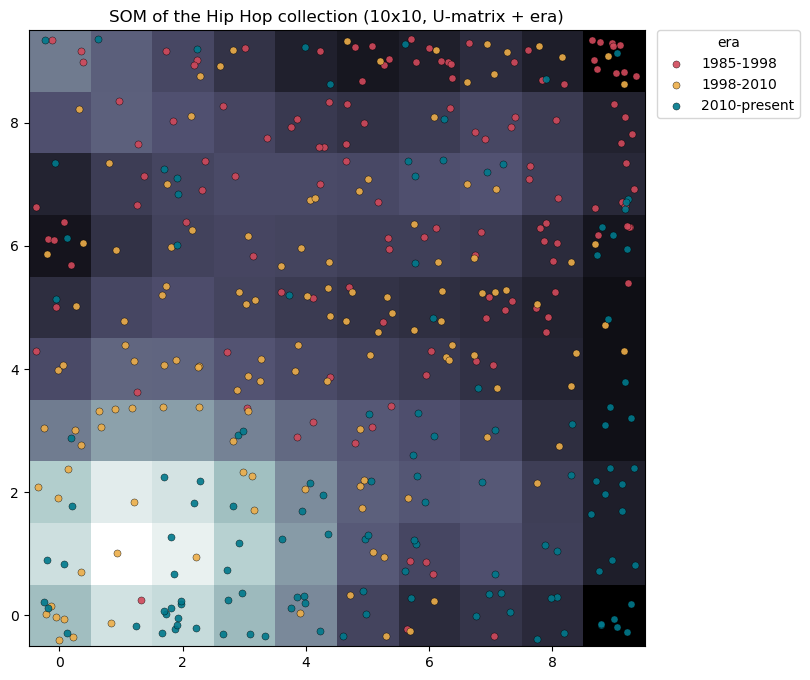

In [7]:
som = IncrementalMap((grid, grid, X.shape[1]),
                     n_iter=200, eta=0.1, nhr=max(2, grid // 2), seed=42)
som.fit(X)

um = som.umatrix()
bmu, _ = best_match(som.weights, X, som.metric)
px, py = np.unravel_index(bmu, som.shape)

colors = {"1985-1998": "#d1495b", "1998-2010": "#edae49", "2010-present": "#00798c"}
jit = np.random.default_rng(0).uniform(-0.4, 0.4, size=(len(px), 2))

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(um, origin="lower", cmap="bone")
for e, c in colors.items():
    m = era == e
    ax.scatter(py[m] + jit[m, 1], px[m] + jit[m, 0], s=26, c=c, label=e,
               edgecolors="k", linewidths=0.3, alpha=0.9)
ax.legend(title="era", loc="upper left", bbox_to_anchor=(1.02, 1),
          borderaxespad=0.)
ax.set_title(f"SOM of the Hip Hop collection ({grid}x{grid}, U-matrix + era)")
plt.show()

## 6. How well do the eras separate? (cross-validated)

The honest test of "do the eras cluster" is to **hold out** tracks: train the
map on the rest, label each unit by the majority era of the *training* tracks on
it, then predict the held-out tracks from their units. This gives no credit for
memorising and is what selected the default features. (Chance = 0.33.)

In [8]:
def cv_som_era_accuracy(X, era, grid, n_iter=120, folds=5, seed=0):
    skf = StratifiedKFold(folds, shuffle=True, random_state=seed)
    accs = []
    for tr, te in skf.split(X, era):
        s = IncrementalMap((grid, grid, X.shape[1]), n_iter=n_iter, eta=0.1,
                           nhr=max(2, grid // 2), seed=42)
        s.fit(X[tr])
        btr, _ = best_match(s.weights, X[tr], s.metric)
        cell = {}
        for b, e in zip(btr, era[tr]):
            cell.setdefault(b, Counter())[e] += 1
        cell = {b: c.most_common(1)[0][0] for b, c in cell.items()}
        fallback = Counter(era[tr]).most_common(1)[0][0]
        bte, _ = best_match(s.weights, X[te], s.metric)
        pred = [cell.get(b, fallback) for b in bte]
        accs.append(np.mean([p == t for p, t in zip(pred, era[te])]))
    return float(np.mean(accs))

acc = cv_som_era_accuracy(X, era, grid)
print(f"cross-validated SOM era accuracy: {acc:.3f}  (chance 0.333)")

cross-validated SOM era accuracy: 0.579  (chance 0.333)


## 7. Where each era concentrates + component planes

Left three panels: the **density of each era** on the map (smoothed hit counts) —
the clearest view of the year clustering. Then one **component plane** per
selected feature: a feature's trained weight across the grid, showing how the
era regions line up with feature gradients.

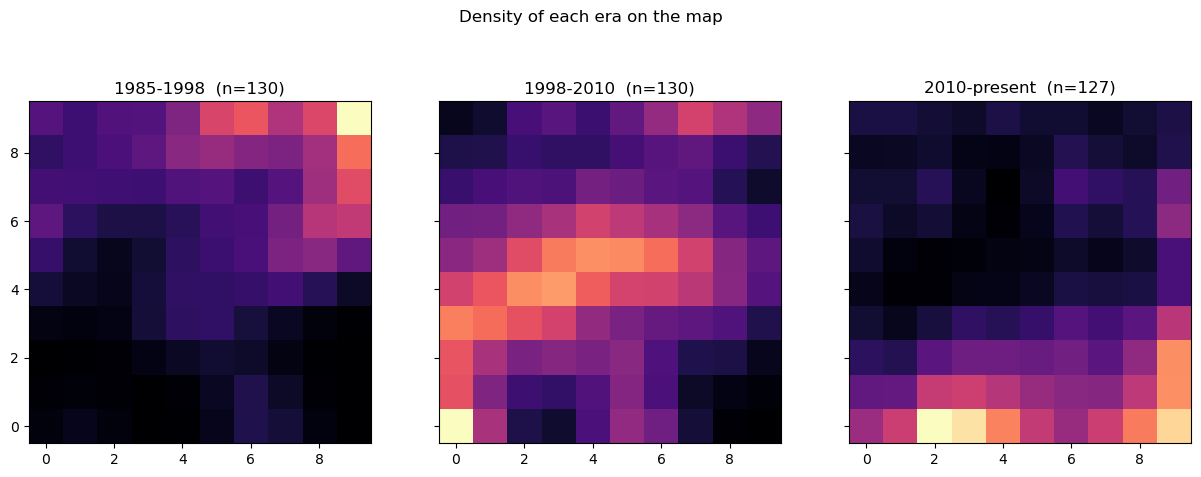

In [9]:
from scipy.ndimage import gaussian_filter

fig, axs = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, e in zip(axs, colors):
    dens = np.zeros(som.shape)
    for r, c in zip(px[era == e], py[era == e]):
        dens[r, c] += 1
    ax.imshow(gaussian_filter(dens, 0.8), origin="lower", cmap="magma")
    ax.set_title(f"{e}  (n={int((era == e).sum())})")
fig.suptitle("Density of each era on the map", y=1.02)
plt.show()

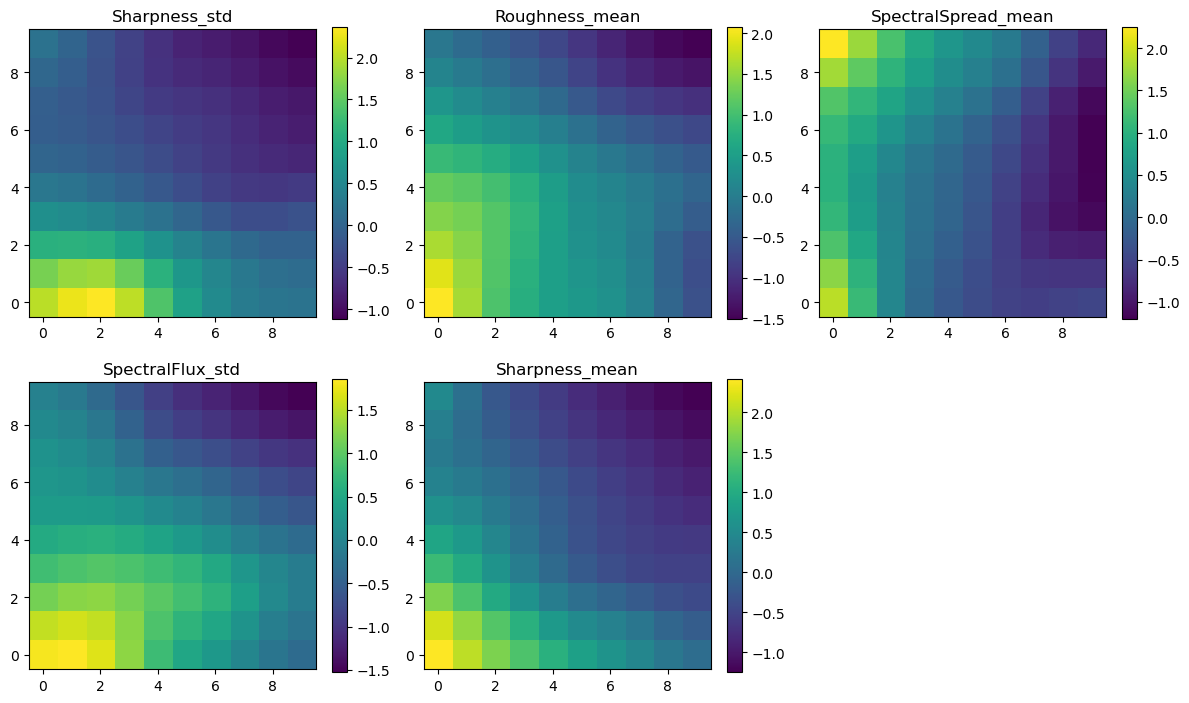

In [10]:
n = len(selected_features)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.6 * nrows),
                        squeeze=False)
for k, f in enumerate(selected_features):
    ax = axs[k // ncols][k % ncols]
    im = ax.imshow(som.weights[:, k].reshape(som.shape), origin="lower",
                   cmap="viridis")
    ax.set_title(f)
    fig.colorbar(im, ax=ax, fraction=0.046)
for k in range(n, nrows * ncols):
    axs[k // ncols][k % ncols].axis("off")
fig.tight_layout()
plt.show()

## 8. What distinguishes the eras (read from the maps)

Reading the per-era density maps together with the component planes — and
confirmed by the average of each standardized feature per era (values in
standard deviations from the collection mean) — the three eras differ in
consistent ways. These are *tendencies*; the eras overlap.

- **1985-1998 - the most distinct: a darker, steadier sound.** It sits low on
  almost every feature: low `Sharpness_mean` (-0.5) and especially low
  `Sharpness_std` (-0.6), low `SpectralFlux_std` (-0.6) and below-average
  `Roughness_mean` (-0.4). So the earliest Hip Hop is duller (less bright), and
  its brightness and spectral content change little within a track - a steady,
  warm timbre. This is why it occupies its own region on the map.

- **1998-2010 - the roughest, broadest era.** Highest `Roughness_mean` (+0.5)
  and the widest `SpectralSpread_mean` (+0.2), with sharpness near the average -
  a dense, rough, full-band texture (the sample-heavy "boom-bap" era).

- **2010-present - the brightest and most dynamic.** Highest `Sharpness_mean`
  (+0.4) and by far the most *variable* sharpness (`Sharpness_std` +0.7) and
  spectral flux (`SpectralFlux_std` +0.4), but the **narrowest** spectral spread
  (-0.2) - a crisp, bright sound with strong moment-to-moment variation
  (hi-hats / transients) over a narrower band, consistent with modern trap
  production.

In short: brightness (sharpness) rises across the eras and, more tellingly, so
does its *variability*, while the middle era stands out by roughness. These are
exactly the gradients in the `Sharpness_*` and `Roughness_mean` component planes,
and they line up with the era-density peaks above.

## 9. How `HipHop_features.csv` was produced (reference)

For reproducibility — the shipped table was built from the per-track
`TimbreTrack` CSVs of the collection (one CSV per piece, grouped in a folder per
era). It needs the private audio analysis, so it is *not* run here:

```python
import glob, os, pandas as pd

# One folder of per-track TimbreTrack CSVs per era (edit to your layout):
ERAS = {"1985-1998": "<folder for 1985-1998>",
        "1998-2010": "<folder for 1998-2010>",
        "2010-present": "<folder for 2010-present>"}
FEAT = ["SpectralCentroid", "SpectralSpread", "SpectralFlux", "Roughness",
        "Sharpness", "SPL", "CorrelationDimension"]

rows = []
for era, folder in ERAS.items():
    for f in glob.glob(os.path.join(folder, "*.csv")):
        df = pd.read_csv(f, index_col=0)
        if df.shape[1] != 7:          # skip non-TimbreTrack CSVs
            continue
        df.columns = FEAT
        rec = {"track": os.path.splitext(os.path.basename(f))[0], "era": era}
        for name in FEAT:
            rec[name + "_mean"] = df[name].mean()
            rec[name + "_std"] = df[name].std()
        rows.append(rec)

pd.DataFrame(rows).to_csv("HipHop_features.csv", index=False)
```

Each per-track CSV is a `TimbreTrack` extraction (see
`TimbreTrack_SimpleExample.ipynb`); the seven columns are the features from
section 1, and `CorrelationDimension` is the fractal dimension.